
# MarketPulse AI — Strategy Analysis

## Stock Markets Analytics Zoomcamp 2026 — Capstone Project

### Objective

Evaluate the out-of-sample performance of the MarketPulse AI trading strategy using the corrected backtest results.

### Analysis Scope

1. Load and verify backtest artifacts
2. Analyze executed trades and return distribution
3. Evaluate performance by ticker
4. Analyze portfolio exposure and drawdowns
5. Compare risk-adjusted performance against SPY
6. Document methodological limitations and conclusions

### Strategy Configuration

- Model: RandomForestClassifier
- Prediction horizon: 10 trading days
- Signal threshold: 0.60
- Maximum concurrent positions: 10
- Fixed allocation per position: $10,000
- Initial capital: $100,000
- Backtest period: July 2025 – November 2026

**Note:** All results are simulated and subject to the documented methodology limitations.


In [1]:

# Cell 1 - Load and Verify Backtest Artifacts

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("MARKETPULSE AI - STRATEGY ANALYSIS")
print("-" * 55)

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

results_dir = project_root / "results"

assert results_dir.exists(), (
    f"Results directory not found: {results_dir}"
)

# Load corrected backtest artifacts
trades = pd.read_parquet(
    results_dir / "marketpulse_executed_trades.parquet"
)

portfolio = pd.read_parquet(
    results_dir / "marketpulse_portfolio_daily.parquet"
)

benchmark = pd.read_parquet(
    results_dir / "marketpulse_benchmark_daily.parquet"
)

performance = pd.read_csv(
    results_dir / "marketpulse_performance_comparison.csv",
    index_col=0
)

print("\nPROJECT DIRECTORY")
print(project_root)

print("\nLOADED DATASETS")
print("Executed trades:", trades.shape)
print("Portfolio daily:", portfolio.shape)
print("Benchmark daily:", benchmark.shape)
print("Performance comparison:", performance.shape)

# Verify saved results
assert len(trades) == 299
assert len(portfolio) == 329
assert len(benchmark) == 329

assert abs(
    portfolio["equity"].iloc[-1] - 125326.20
) < 0.01

print("\nEXECUTED TRADE COLUMNS")
print(trades.columns.tolist())

print("\nPORTFOLIO COLUMNS")
print(portfolio.columns.tolist())

print("\nBENCHMARK COLUMNS")
print(benchmark.columns.tolist())

print("\nPERFORMANCE COMPARISON")
display(performance.round(4))

print("\nCell 1 verification: PASSED")
print("Strategy analysis datasets ready.")


MARKETPULSE AI - STRATEGY ANALYSIS
-------------------------------------------------------

PROJECT DIRECTORY
C:\Users\roban\marketpulse-ai

LOADED DATASETS
Executed trades: (299, 8)
Portfolio daily: (329, 9)
Benchmark daily: (329, 12)
Performance comparison: (7, 2)

EXECUTED TRADE COLUMNS
['ticker', 'signal_date', 'entry_date', 'exit_date', 'predicted_probability', 'allocated_capital', 'net_return', 'pnl']

PORTFOLIO COLUMNS
['date', 'cash', 'market_value', 'equity', 'open_positions', 'daily_return', 'cumulative_return', 'running_peak', 'drawdown']

BENCHMARK COLUMNS
['date', 'cash', 'market_value', 'equity', 'open_positions', 'daily_return', 'cumulative_return', 'running_peak', 'drawdown', 'spy_equity', 'strategy_return', 'spy_return']

PERFORMANCE COMPARISON


,MarketPulse_AI,SPY_Buy_Hold
Cumulative_Return,0.2533,0.2258
Annualized_Return,0.1894,0.1693
Annualized_Volatility,0.1069,0.1230
Sharpe_Ratio,1.6768,1.3292
Maximum_Drawdown,-0.0524,-0.0888
Positive_Day_Rate,0.5671,0.5305
Trading_Days,328.0000,328.0000



Cell 1 verification: PASSED
Strategy analysis datasets ready.


MARKETPULSE AI - TRADE RETURN DISTRIBUTION
-------------------------------------------------------

TRADE PERFORMANCE SUMMARY


,Metric,Value
0,Total Trades,299
1,Winning Trades,155
2,Losing Trades,144
3,Breakeven Trades,0
4,Win Rate,51.84%
5,Average Net Return,0.85%
6,Median Net Return,0.39%
7,Best Trade Return,29.53%
8,Worst Trade Return,-18.54%
9,Average Winning Return,5.51%


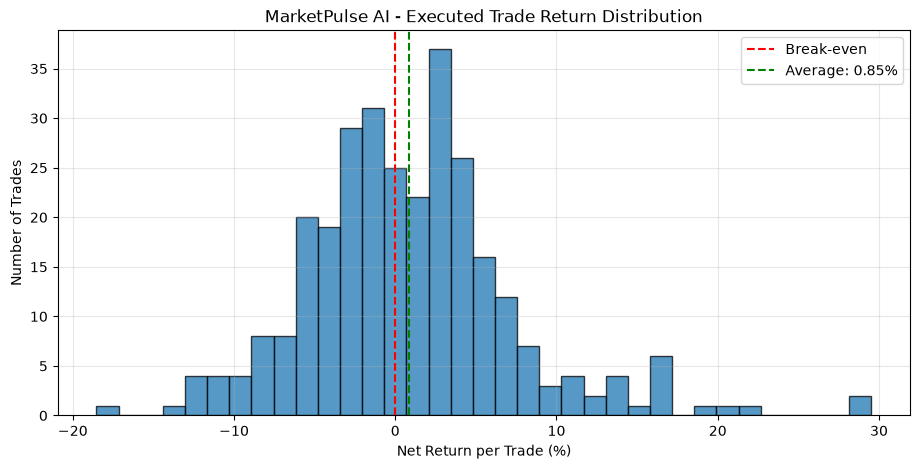


Cell 2 verification: PASSED
Trade distribution analysis completed.


In [2]:

# Cell 2 - Trade Return Distribution Analysis

print("MARKETPULSE AI - TRADE RETURN DISTRIBUTION")
print("-" * 55)

# Work with a copy of executed trades
trade_analysis = trades.copy()

# Verify required columns
required_columns = [
    "ticker",
    "net_return",
    "pnl",
    "allocated_capital"
]

assert all(
    col in trade_analysis.columns
    for col in required_columns
)

# Separate winning and losing trades
winning_trades = trade_analysis[
    trade_analysis["pnl"] > 0
]

losing_trades = trade_analysis[
    trade_analysis["pnl"] < 0
]

breakeven_trades = trade_analysis[
    trade_analysis["pnl"] == 0
]

# Calculate trade statistics
total_trades = len(trade_analysis)

win_rate = len(winning_trades) / total_trades

average_return = trade_analysis["net_return"].mean()
median_return = trade_analysis["net_return"].median()

best_return = trade_analysis["net_return"].max()
worst_return = trade_analysis["net_return"].min()

average_win = winning_trades["net_return"].mean()
average_loss = losing_trades["net_return"].mean()

gross_profit = winning_trades["pnl"].sum()
gross_loss = abs(losing_trades["pnl"].sum())

profit_factor = (
    gross_profit / gross_loss
    if gross_loss > 0 else np.inf
)

total_pnl = trade_analysis["pnl"].sum()

# Display summary
trade_summary = pd.DataFrame({
    "Metric": [
        "Total Trades",
        "Winning Trades",
        "Losing Trades",
        "Breakeven Trades",
        "Win Rate",
        "Average Net Return",
        "Median Net Return",
        "Best Trade Return",
        "Worst Trade Return",
        "Average Winning Return",
        "Average Losing Return",
        "Gross Profit ($)",
        "Gross Loss ($)",
        "Profit Factor",
        "Total Net P&L ($)"
    ],
    "Value": [
        total_trades,
        len(winning_trades),
        len(losing_trades),
        len(breakeven_trades),
        f"{win_rate:.2%}",
        f"{average_return:.2%}",
        f"{median_return:.2%}",
        f"{best_return:.2%}",
        f"{worst_return:.2%}",
        f"{average_win:.2%}",
        f"{average_loss:.2%}",
        round(gross_profit, 2),
        round(gross_loss, 2),
        round(profit_factor, 4),
        round(total_pnl, 2)
    ]
})

print("\nTRADE PERFORMANCE SUMMARY")
display(trade_summary)

# Plot trade return distribution
plt.figure(figsize=(11, 5))

plt.hist(
    trade_analysis["net_return"] * 100,
    bins=35,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Break-even"
)

plt.axvline(
    average_return * 100,
    color="green",
    linestyle="--",
    label=f"Average: {average_return:.2%}"
)

plt.title("MarketPulse AI - Executed Trade Return Distribution")
plt.xlabel("Net Return per Trade (%)")
plt.ylabel("Number of Trades")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Verify against corrected backtest
assert total_trades == 299

assert abs(total_pnl - 25326.20) < 0.01

assert (
    len(winning_trades)
    + len(losing_trades)
    + len(breakeven_trades)
) == total_trades

print("\nCell 2 verification: PASSED")
print("Trade distribution analysis completed.")


MARKETPULSE AI - PERFORMANCE BY TICKER
-------------------------------------------------------

TICKER PERFORMANCE SUMMARY


,ticker,total_trades,winning_trades,losing_trades,average_return,median_return,total_pnl,win_rate,pnl_contribution_pct
0,UNH,16,9,7,3.04,1.06,4865.54,56.25,19.21
1,WMT,28,16,12,1.06,0.20,2980.63,57.14,11.77
2,JNJ,9,7,2,3.05,2.84,2743.88,77.78,10.83
3,META,13,6,7,1.96,-3.14,2552.37,46.15,10.08
4,XOM,17,8,9,1.47,-0.11,2500.01,47.06,9.87
5,GOOGL,17,10,7,1.46,3.13,2481.69,58.82,9.80
6,MSFT,18,7,11,1.27,-1.64,2277.61,38.89,8.99
7,GE,12,7,5,1.56,1.24,1875.83,58.33,7.41
8,CAT,14,8,6,1.16,1.09,1619.90,57.14,6.40
9,JPM,10,5,5,1.42,0.76,1416.08,50.00,5.59


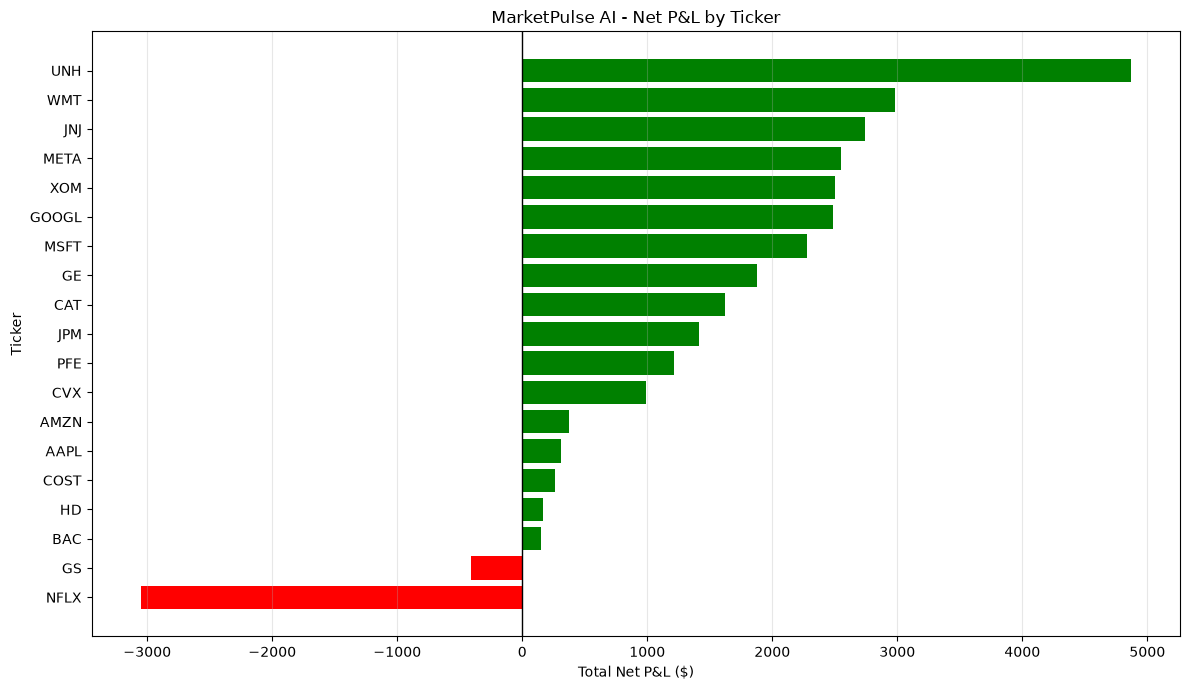


PORTFOLIO CONTRIBUTION VERIFICATION
Tickers traded: 19
Ticker P&L total: $25,326.20
Portfolio P&L: $25,326.20

TOP 5 PROFIT CONTRIBUTORS


,ticker,total_trades,total_pnl,pnl_contribution_pct
0,UNH,16,4865.54,19.21
1,WMT,28,2980.63,11.77
2,JNJ,9,2743.88,10.83
3,META,13,2552.37,10.08
4,XOM,17,2500.01,9.87



BOTTOM 5 PROFIT CONTRIBUTORS


,ticker,total_trades,total_pnl,pnl_contribution_pct
14,COST,24,261.43,1.03
15,HD,16,167.04,0.66
16,BAC,20,151.23,0.60
17,GS,19,-407.88,-1.61
18,NFLX,23,-3048.87,-12.04



Cell 3 verification: PASSED
Ticker-level performance analysis completed.


In [3]:

# Cell 3 - Performance by Ticker

print("MARKETPULSE AI - PERFORMANCE BY TICKER")
print("-" * 55)

# Group executed trades by ticker
ticker_performance = (
    trade_analysis
    .groupby("ticker")
    .agg(
        total_trades=("pnl", "count"),
        winning_trades=("pnl", lambda x: (x > 0).sum()),
        losing_trades=("pnl", lambda x: (x < 0).sum()),
        average_return=("net_return", "mean"),
        median_return=("net_return", "median"),
        total_pnl=("pnl", "sum")
    )
    .reset_index()
)

# Calculate win rate
ticker_performance["win_rate"] = (
    ticker_performance["winning_trades"]
    / ticker_performance["total_trades"]
)

# Calculate contribution to net portfolio profit
ticker_performance["pnl_contribution_pct"] = (
    ticker_performance["total_pnl"]
    / trade_analysis["pnl"].sum()
    * 100
)

# Sort by total P&L
ticker_performance = ticker_performance.sort_values(
    "total_pnl",
    ascending=False
).reset_index(drop=True)

# Create display table
ticker_display = ticker_performance.copy()

ticker_display["average_return"] = (
    ticker_display["average_return"] * 100
)

ticker_display["median_return"] = (
    ticker_display["median_return"] * 100
)

ticker_display["win_rate"] = (
    ticker_display["win_rate"] * 100
)

print("\nTICKER PERFORMANCE SUMMARY")
display(ticker_display.round(2))

# Plot ticker contribution to portfolio P&L
plt.figure(figsize=(12, 7))

colors = [
    "green" if pnl >= 0 else "red"
    for pnl in ticker_performance["total_pnl"]
]

plt.barh(
    ticker_performance["ticker"],
    ticker_performance["total_pnl"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.title("MarketPulse AI - Net P&L by Ticker")
plt.xlabel("Total Net P&L ($)")
plt.ylabel("Ticker")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Portfolio contribution checks
print("\nPORTFOLIO CONTRIBUTION VERIFICATION")

ticker_total_pnl = ticker_performance["total_pnl"].sum()
portfolio_total_pnl = trade_analysis["pnl"].sum()

print("Tickers traded:", len(ticker_performance))
print("Ticker P&L total:", f"${ticker_total_pnl:,.2f}")
print("Portfolio P&L:", f"${portfolio_total_pnl:,.2f}")

print("\nTOP 5 PROFIT CONTRIBUTORS")
display(
    ticker_performance[
        ["ticker", "total_trades", "total_pnl",
         "pnl_contribution_pct"]
    ].head(5).round(2)
)

print("\nBOTTOM 5 PROFIT CONTRIBUTORS")
display(
    ticker_performance[
        ["ticker", "total_trades", "total_pnl",
         "pnl_contribution_pct"]
    ].tail(5).round(2)
)

assert abs(
    ticker_total_pnl - portfolio_total_pnl
) < 0.01

assert ticker_performance["total_trades"].sum() == 299

print("\nCell 3 verification: PASSED")
print("Ticker-level performance analysis completed.")


MARKETPULSE AI - PROFIT CONCENTRATION ANALYSIS
-------------------------------------------------------

PROFIT CONCENTRATION SUMMARY


,Top_N_Trades,Top_Trade_PnL,Pct_of_Net_Profit,Remaining_Trade_PnL
0,1,2952.71,11.66,22373.49
1,5,11989.88,47.34,13336.32
2,10,20084.51,79.30,5241.69
3,20,33332.59,131.61,-8006.39



TOP 10 WINNING TRADES


C:\Users\roban\AppData\Local\Temp\ipykernel_7216\2442143944.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(4)


,ticker,entry_date,exit_date,net_return,pnl
0,NFLX,2026-02-20,2026-03-06,0.2953,2952.7112
1,MSFT,2026-07-27,2026-08-10,0.2893,2893.1716
2,META,2026-06-26,2026-07-13,0.2160,2160.3214
3,UNH,2025-08-01,2025-08-15,0.2027,2026.9916
4,AMZN,2026-07-28,2026-08-11,0.1957,1956.6865
5,AMZN,2025-10-17,2025-10-31,0.1645,1644.7630
6,META,2026-03-27,2026-04-13,0.1644,1643.6016
7,GOOGL,2025-08-21,2025-09-05,0.1613,1612.9129
8,UNH,2025-08-27,2025-09-11,0.1601,1600.8236
9,UNH,2026-03-24,2026-04-08,0.1593,1592.5228



TOP 10 LOSING TRADES


C:\Users\roban\AppData\Local\Temp\ipykernel_7216\2442143944.py:61: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).sort_values("pnl").round(4)


,ticker,entry_date,exit_date,net_return,pnl
298,GOOGL,2026-10-20,2026-11-03,-0.1854,-1853.6323
297,META,2026-03-13,2026-03-27,-0.1344,-1344.2735
296,UNH,2025-07-18,2025-08-01,-0.1304,-1303.6403
295,AMZN,2026-01-26,2026-02-09,-0.1301,-1300.8943
294,GS,2026-07-16,2026-07-30,-0.1231,-1231.1848
293,CAT,2026-10-15,2026-10-29,-0.1220,-1220.0361
292,NFLX,2025-11-20,2025-12-05,-0.1110,-1109.7957
291,BAC,2026-09-11,2026-09-25,-0.1103,-1103.3181
290,UNH,2025-10-21,2025-11-04,-0.1036,-1036.2461
289,COST,2026-05-18,2026-06-02,-0.1035,-1034.7796


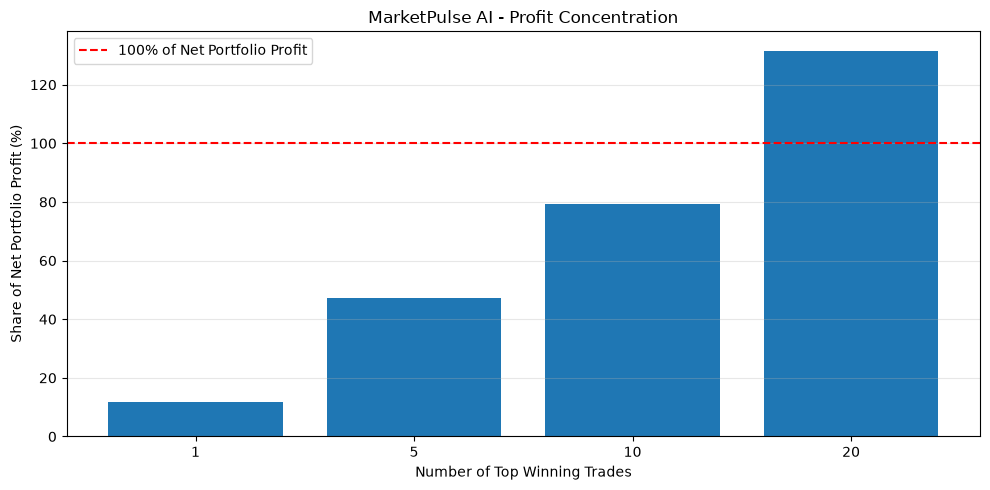


Cell 4 verification: PASSED
Profit concentration analysis completed.


In [4]:

# Cell 4 - Profit Concentration Analysis

print("MARKETPULSE AI - PROFIT CONCENTRATION ANALYSIS")
print("-" * 55)

# Sort executed trades by realized P&L
ranked_trades = trade_analysis.sort_values(
    "pnl", ascending=False
).reset_index(drop=True)

total_net_pnl = ranked_trades["pnl"].sum()

concentration_rows = []

for n in [1, 5, 10, 20]:
    top_profit = ranked_trades.head(n)["pnl"].sum()

    concentration_rows.append({
        "Top_N_Trades": n,
        "Top_Trade_PnL": top_profit,
        "Pct_of_Net_Profit": (
            top_profit / total_net_pnl * 100
        ),
        "Remaining_Trade_PnL": (
            total_net_pnl - top_profit
        )
    })

concentration_df = pd.DataFrame(concentration_rows)

print("\nPROFIT CONCENTRATION SUMMARY")
display(concentration_df.round(2))

# Identify the largest winning trades
print("\nTOP 10 WINNING TRADES")

display(
    ranked_trades[
        [
            "ticker",
            "entry_date",
            "exit_date",
            "net_return",
            "pnl"
        ]
    ].head(10).round(4)
)

# Identify the largest losing trades
print("\nTOP 10 LOSING TRADES")

display(
    ranked_trades[
        [
            "ticker",
            "entry_date",
            "exit_date",
            "net_return",
            "pnl"
        ]
    ].tail(10).sort_values("pnl").round(4)
)

# Plot concentration
plt.figure(figsize=(10, 5))

plt.bar(
    concentration_df["Top_N_Trades"].astype(str),
    concentration_df["Pct_of_Net_Profit"]
)

plt.axhline(
    100,
    color="red",
    linestyle="--",
    label="100% of Net Portfolio Profit"
)

plt.title("MarketPulse AI - Profit Concentration")
plt.xlabel("Number of Top Winning Trades")
plt.ylabel("Share of Net Portfolio Profit (%)")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Verify calculations
assert len(ranked_trades) == 299

assert abs(total_net_pnl - 25326.20) < 0.01

assert np.isclose(
    concentration_df.loc[
        concentration_df["Top_N_Trades"] == 10,
        "Top_Trade_PnL"
    ].iloc[0]
    +
    concentration_df.loc[
        concentration_df["Top_N_Trades"] == 10,
        "Remaining_Trade_PnL"
    ].iloc[0],
    total_net_pnl
)

print("\nCell 4 verification: PASSED")
print("Profit concentration analysis completed.")


MARKETPULSE AI - PORTFOLIO EXPOSURE ANALYSIS
-------------------------------------------------------

PORTFOLIO EXPOSURE SUMMARY


,Metric,Value
0,Total Trading Days,329.00
1,Average Open Positions,9.09
2,Maximum Open Positions,10.00
3,Days Fully Invested (10 Positions),185.00
4,Days With No Positions,2.00
5,Average Invested Capital (%),78.91
6,Median Invested Capital (%),81.54
7,Maximum Invested Capital (%),100.00
8,Average Cash (%),21.09
9,Minimum Cash ($),0.00



OPEN POSITION DISTRIBUTION


,Open_Positions,Trading_Days,Pct_of_Days
0,0,2,0.61
1,1,1,0.30
2,3,1,0.30
3,5,2,0.61
4,6,16,4.86
5,7,14,4.26
6,8,40,12.16
7,9,68,20.67
8,10,185,56.23


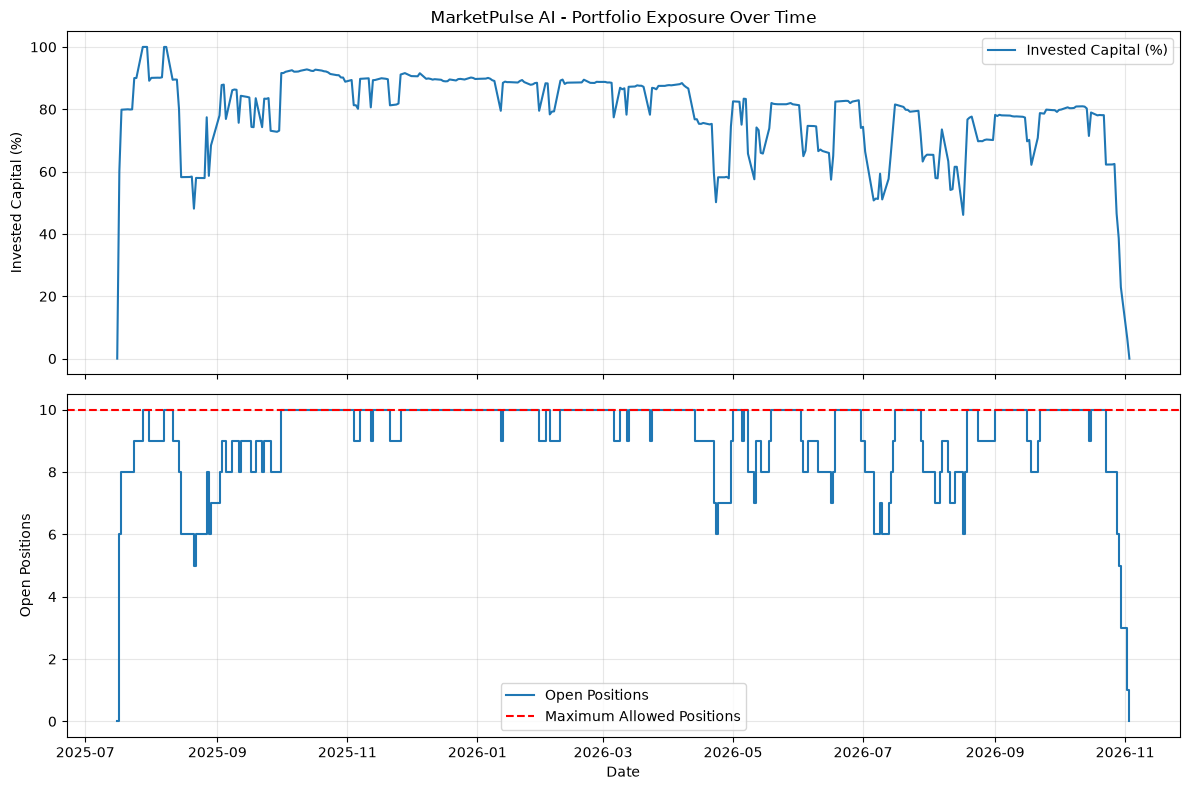


Cell 5 verification: PASSED
Portfolio exposure analysis completed.


In [5]:

# Cell 5 - Portfolio Exposure Analysis

print("MARKETPULSE AI - PORTFOLIO EXPOSURE ANALYSIS")
print("-" * 55)

exposure_df = portfolio.copy()

exposure_df["date"] = pd.to_datetime(
    exposure_df["date"]
)

exposure_df = exposure_df.sort_values(
    "date"
).reset_index(drop=True)

# Calculate invested capital percentage
exposure_df["invested_pct"] = (
    exposure_df["market_value"]
    / exposure_df["equity"]
    * 100
)

# Calculate cash percentage
exposure_df["cash_pct"] = (
    exposure_df["cash"]
    / exposure_df["equity"]
    * 100
)

# Summary statistics
exposure_summary = pd.DataFrame({
    "Metric": [
        "Total Trading Days",
        "Average Open Positions",
        "Maximum Open Positions",
        "Days Fully Invested (10 Positions)",
        "Days With No Positions",
        "Average Invested Capital (%)",
        "Median Invested Capital (%)",
        "Maximum Invested Capital (%)",
        "Average Cash (%)",
        "Minimum Cash ($)"
    ],
    "Value": [
        len(exposure_df),
        exposure_df["open_positions"].mean(),
        exposure_df["open_positions"].max(),
        (exposure_df["open_positions"] == 10).sum(),
        (exposure_df["open_positions"] == 0).sum(),
        exposure_df["invested_pct"].mean(),
        exposure_df["invested_pct"].median(),
        exposure_df["invested_pct"].max(),
        exposure_df["cash_pct"].mean(),
        exposure_df["cash"].min()
    ]
})

print("\nPORTFOLIO EXPOSURE SUMMARY")
display(exposure_summary.round(2))

# Position count distribution
position_distribution = (
    exposure_df["open_positions"]
    .value_counts()
    .sort_index()
    .rename_axis("Open_Positions")
    .reset_index(name="Trading_Days")
)

position_distribution["Pct_of_Days"] = (
    position_distribution["Trading_Days"]
    / len(exposure_df)
    * 100
)

print("\nOPEN POSITION DISTRIBUTION")
display(position_distribution.round(2))

# Plot exposure over time
fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

axes[0].plot(
    exposure_df["date"],
    exposure_df["invested_pct"],
    label="Invested Capital (%)"
)

axes[0].set_ylabel("Invested Capital (%)")
axes[0].set_title(
    "MarketPulse AI - Portfolio Exposure Over Time"
)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].step(
    exposure_df["date"],
    exposure_df["open_positions"],
    where="post",
    label="Open Positions"
)

axes[1].axhline(
    10,
    linestyle="--",
    color="red",
    label="Maximum Allowed Positions"
)

axes[1].set_ylabel("Open Positions")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# Verification
assert len(exposure_df) == 329

assert exposure_df["open_positions"].max() <= 10

assert exposure_df["cash"].min() >= -1e-6

assert np.allclose(
    exposure_df["invested_pct"]
    + exposure_df["cash_pct"],
    100,
    atol=1e-6
)

print("\nCell 5 verification: PASSED")
print("Portfolio exposure analysis completed.")


MARKETPULSE AI - DRAWDOWN AND RECOVERY ANALYSIS
-------------------------------------------------------

DRAWDOWN SUMMARY


,Metric,MarketPulse_AI,SPY_Buy_Hold
0,Maximum Drawdown,-5.24%,-8.88%
1,Peak Date,2026-08-12 00:00:00,2026-01-27 00:00:00
2,Trough Date,2026-09-30 00:00:00,2026-03-30 00:00:00
3,Recovery Date,NaT,2026-04-14 00:00:00
4,Recovered,False,True
5,Recovery Trading Days,NaN,10


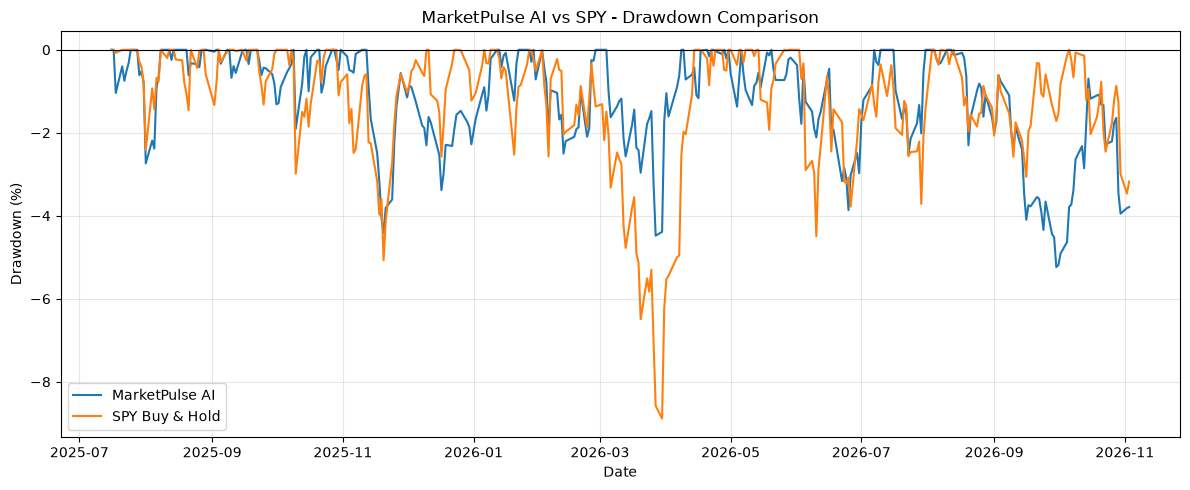


Cell 6 verification: PASSED
Drawdown and recovery analysis completed.


In [6]:

# Cell 6 - Drawdown and Recovery Analysis

print("MARKETPULSE AI - DRAWDOWN AND RECOVERY ANALYSIS")
print("-" * 55)

drawdown_df = benchmark.copy()

drawdown_df["date"] = pd.to_datetime(
    drawdown_df["date"]
)

drawdown_df = drawdown_df.sort_values(
    "date"
).reset_index(drop=True)

initial_capital = 100000.0

# Calculate drawdowns from running equity peaks,
# including initial capital as a reference.
def analyze_drawdown(equity, dates, starting_capital):

    equity = pd.Series(equity).reset_index(drop=True)
    dates = pd.to_datetime(
        pd.Series(dates).reset_index(drop=True)
    )

    running_peak = equity.cummax().clip(
        lower=starting_capital
    )

    drawdown = equity / running_peak - 1

    trough_idx = drawdown.idxmin()
    trough_date = dates.iloc[trough_idx]

    peak_value = running_peak.iloc[trough_idx]

    # Last date at the preceding peak level
    prior_peak_indices = np.flatnonzero(
        np.isclose(
            equity.iloc[:trough_idx + 1],
            peak_value,
            rtol=1e-10,
            atol=0.01
        )
    )

    peak_idx = (
        int(prior_peak_indices[-1])
        if len(prior_peak_indices) > 0
        else None
    )

    # Find recovery to the previous peak
    recovery_candidates = np.flatnonzero(
        equity.iloc[trough_idx + 1:].to_numpy()
        >= peak_value
    )

    if len(recovery_candidates) > 0:
        recovery_idx = (
            trough_idx + 1 + recovery_candidates[0]
        )
        recovery_date = dates.iloc[recovery_idx]
        recovered = True
    else:
        recovery_idx = None
        recovery_date = pd.NaT
        recovered = False

    return {
        "max_drawdown": drawdown.min(),
        "peak_date": (
            dates.iloc[peak_idx]
            if peak_idx is not None else pd.NaT
        ),
        "trough_date": trough_date,
        "recovery_date": recovery_date,
        "recovered": recovered,
        "recovery_trading_days": (
            recovery_idx - trough_idx
            if recovered else np.nan
        ),
        "drawdown_series": drawdown
    }

strategy_dd = analyze_drawdown(
    drawdown_df["equity"],
    drawdown_df["date"],
    initial_capital
)

spy_dd = analyze_drawdown(
    drawdown_df["spy_equity"],
    drawdown_df["date"],
    initial_capital
)

# Display summary
drawdown_summary = pd.DataFrame({
    "Metric": [
        "Maximum Drawdown",
        "Peak Date",
        "Trough Date",
        "Recovery Date",
        "Recovered",
        "Recovery Trading Days"
    ],
    "MarketPulse_AI": [
        f"{strategy_dd['max_drawdown']:.2%}",
        strategy_dd["peak_date"],
        strategy_dd["trough_date"],
        strategy_dd["recovery_date"],
        strategy_dd["recovered"],
        strategy_dd["recovery_trading_days"]
    ],
    "SPY_Buy_Hold": [
        f"{spy_dd['max_drawdown']:.2%}",
        spy_dd["peak_date"],
        spy_dd["trough_date"],
        spy_dd["recovery_date"],
        spy_dd["recovered"],
        spy_dd["recovery_trading_days"]
    ]
})

print("\nDRAWDOWN SUMMARY")
display(drawdown_summary)

# Plot drawdowns
plt.figure(figsize=(12, 5))

plt.plot(
    drawdown_df["date"],
    strategy_dd["drawdown_series"] * 100,
    label="MarketPulse AI"
)

plt.plot(
    drawdown_df["date"],
    spy_dd["drawdown_series"] * 100,
    label="SPY Buy & Hold"
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8
)

plt.title("MarketPulse AI vs SPY - Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Verification
assert len(drawdown_df) == 329

assert np.isclose(
    strategy_dd["max_drawdown"],
    performance.loc[
        "Maximum_Drawdown", "MarketPulse_AI"
    ],
    atol=1e-4
)

assert np.isclose(
    spy_dd["max_drawdown"],
    performance.loc[
        "Maximum_Drawdown", "SPY_Buy_Hold"
    ],
    atol=1e-4
)

print("\nCell 6 verification: PASSED")
print("Drawdown and recovery analysis completed.")


MARKETPULSE AI - MONTHLY PERFORMANCE ANALYSIS
-------------------------------------------------------

MONTHLY PERFORMANCE TABLE


,month,strategy_monthly_return,spy_monthly_return,excess_return,outperformed
date,,,,,
2025-07-31,2025-07,-0.36,1.34,-1.70,False
2025-08-31,2025-08,4.24,2.05,2.18,True
2025-09-30,2025-09,3.95,3.56,0.38,True
2025-10-31,2025-10,3.61,2.38,1.22,True
2025-11-30,2025-11,0.90,0.19,0.70,True
2025-12-31,2025-12,-1.73,0.08,-1.81,False
2026-01-31,2026-01,3.28,1.47,1.81,True
2026-02-28,2026-02,1.86,-0.86,2.72,True
2026-03-31,2026-03,-1.36,-4.94,3.58,True



MONTHLY PERFORMANCE SUMMARY
Total calendar months: 17
Months strategy outperformed SPY: 10
Outperformance rate: 58.82%
Positive strategy months: 12
Positive SPY months: 11
Best strategy month: 6.76%
Worst strategy month: -3.66%


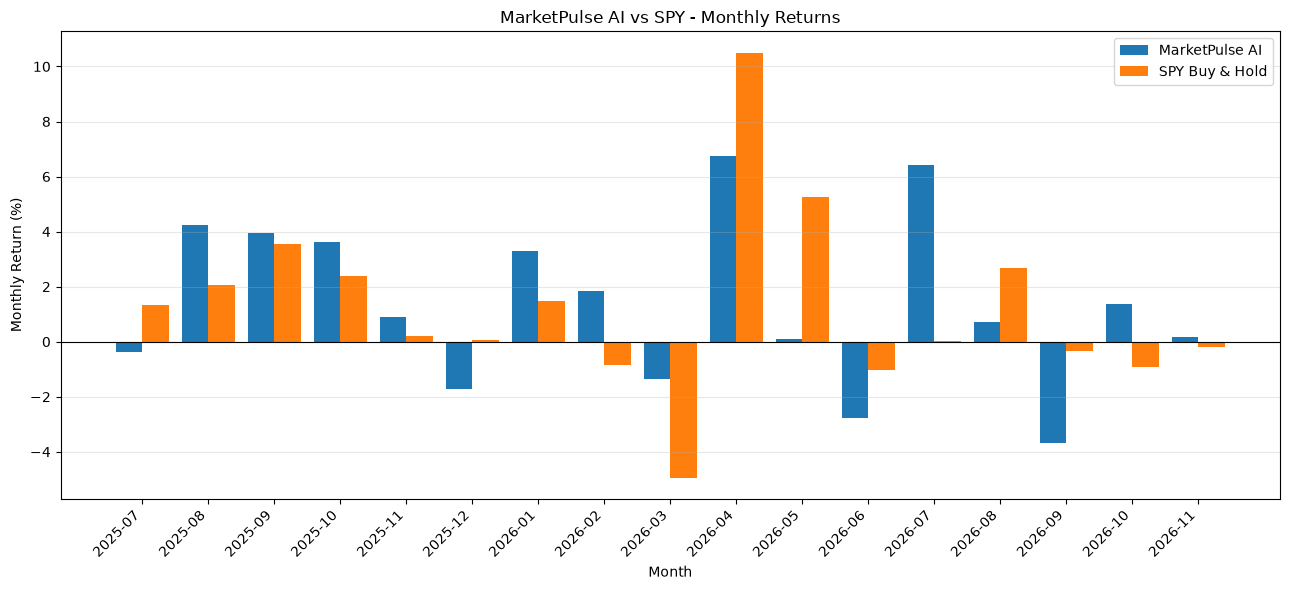


Cell 7 verification: PASSED
Monthly performance analysis completed.


In [7]:

# Cell 7 - Monthly Performance Analysis

print("MARKETPULSE AI - MONTHLY PERFORMANCE ANALYSIS")
print("-" * 55)

monthly_df = benchmark.copy()

monthly_df["date"] = pd.to_datetime(
    monthly_df["date"]
)

monthly_df = monthly_df.sort_values(
    "date"
).reset_index(drop=True)

initial_capital = 100000.0

# Use last available equity value in each month
monthly_equity = (
    monthly_df
    .set_index("date")[["equity", "spy_equity"]]
    .resample("ME")
    .last()
)

# Include initial capital as the starting reference
previous_strategy = monthly_equity["equity"].shift(1)
previous_spy = monthly_equity["spy_equity"].shift(1)

previous_strategy.iloc[0] = initial_capital
previous_spy.iloc[0] = initial_capital

monthly_equity["strategy_monthly_return"] = (
    monthly_equity["equity"] / previous_strategy - 1
)

monthly_equity["spy_monthly_return"] = (
    monthly_equity["spy_equity"] / previous_spy - 1
)

monthly_equity["excess_return"] = (
    monthly_equity["strategy_monthly_return"]
    - monthly_equity["spy_monthly_return"]
)

monthly_equity["outperformed"] = (
    monthly_equity["excess_return"] > 0
)

monthly_equity["month"] = (
    monthly_equity.index.strftime("%Y-%m")
)

print("\nMONTHLY PERFORMANCE TABLE")

monthly_display = monthly_equity[
    [
        "month",
        "strategy_monthly_return",
        "spy_monthly_return",
        "excess_return",
        "outperformed"
    ]
].copy()

for column in [
    "strategy_monthly_return",
    "spy_monthly_return",
    "excess_return"
]:
    monthly_display[column] *= 100

display(monthly_display.round(2))

# Summary statistics
total_months = len(monthly_equity)

months_outperformed = int(
    monthly_equity["outperformed"].sum()
)

strategy_positive_months = int(
    (monthly_equity["strategy_monthly_return"] > 0).sum()
)

spy_positive_months = int(
    (monthly_equity["spy_monthly_return"] > 0).sum()
)

print("\nMONTHLY PERFORMANCE SUMMARY")

print("Total calendar months:", total_months)
print("Months strategy outperformed SPY:", months_outperformed)
print(
    "Outperformance rate:",
    f"{months_outperformed / total_months:.2%}"
)

print("Positive strategy months:", strategy_positive_months)
print("Positive SPY months:", spy_positive_months)

print(
    "Best strategy month:",
    f"{monthly_equity['strategy_monthly_return'].max():.2%}"
)

print(
    "Worst strategy month:",
    f"{monthly_equity['strategy_monthly_return'].min():.2%}"
)

# Plot monthly returns
x = np.arange(total_months)
width = 0.4

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    monthly_equity["strategy_monthly_return"] * 100,
    width,
    label="MarketPulse AI"
)

plt.bar(
    x + width / 2,
    monthly_equity["spy_monthly_return"] * 100,
    width,
    label="SPY Buy & Hold"
)

plt.xticks(
    x,
    monthly_equity["month"],
    rotation=45,
    ha="right"
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("MarketPulse AI vs SPY - Monthly Returns")
plt.xlabel("Month")
plt.ylabel("Monthly Return (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Verify compounded monthly returns
strategy_compounded = (
    1 + monthly_equity["strategy_monthly_return"]
).prod() - 1

spy_compounded = (
    1 + monthly_equity["spy_monthly_return"]
).prod() - 1

assert np.isclose(
    strategy_compounded,
    performance.loc[
        "Cumulative_Return", "MarketPulse_AI"
    ],
    atol=1e-4
)

assert np.isclose(
    spy_compounded,
    performance.loc[
        "Cumulative_Return", "SPY_Buy_Hold"
    ],
    atol=1e-4
)

print("\nCell 7 verification: PASSED")
print("Monthly performance analysis completed.")


MARKETPULSE AI - BENCHMARK RISK ANALYSIS
-------------------------------------------------------

BENCHMARK RISK SUMMARY


,Metric,Value
0,Daily Return Correlation,0.6364
1,Portfolio Beta vs SPY,0.5531
2,Annualized Tracking Error,0.0991
3,Annualized Arithmetic Active Return,0.0157
4,Information Ratio,0.1590
5,Downside Capture Ratio,0.4627
6,Aligned Daily Observations,328.0000


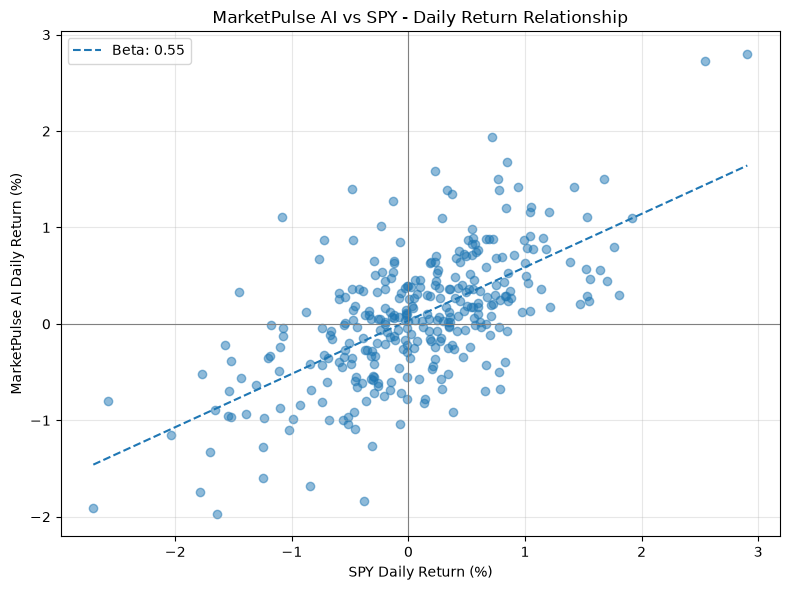


Cell 8 verification: PASSED
Benchmark risk analysis completed.


In [8]:

# Cell 8 - Risk-Adjusted Performance and Benchmark Correlation

print("MARKETPULSE AI - BENCHMARK RISK ANALYSIS")
print("-" * 55)

risk_df = benchmark.copy()

risk_df["date"] = pd.to_datetime(risk_df["date"])
risk_df = risk_df.sort_values("date").reset_index(drop=True)

# Recalculate daily returns from equity
risk_df["strategy_daily_return"] = (
    risk_df["equity"].pct_change()
)

risk_df["spy_daily_return"] = (
    risk_df["spy_equity"].pct_change()
)

# Align valid observations
risk_returns = risk_df[
    ["date", "strategy_daily_return", "spy_daily_return"]
].dropna().copy()

strategy_returns = risk_returns["strategy_daily_return"]
spy_returns = risk_returns["spy_daily_return"]

# Calculate market relationship
correlation = strategy_returns.corr(spy_returns)

spy_variance = spy_returns.var(ddof=1)

beta = (
    strategy_returns.cov(spy_returns) / spy_variance
    if spy_variance > 0 else np.nan
)

# Active returns relative to SPY
risk_returns["active_return"] = (
    strategy_returns - spy_returns
)

tracking_error = (
    risk_returns["active_return"].std(ddof=1)
    * np.sqrt(252)
)

annualized_active_return = (
    risk_returns["active_return"].mean() * 252
)

information_ratio = (
    annualized_active_return / tracking_error
    if tracking_error > 0 else np.nan
)

# Downside capture: strategy vs SPY on negative SPY days
down_market = risk_returns[
    risk_returns["spy_daily_return"] < 0
]

downside_capture = (
    down_market["strategy_daily_return"].mean()
    / down_market["spy_daily_return"].mean()
    if len(down_market) > 0 else np.nan
)

risk_summary = pd.DataFrame({
    "Metric": [
        "Daily Return Correlation",
        "Portfolio Beta vs SPY",
        "Annualized Tracking Error",
        "Annualized Arithmetic Active Return",
        "Information Ratio",
        "Downside Capture Ratio",
        "Aligned Daily Observations"
    ],
    "Value": [
        correlation,
        beta,
        tracking_error,
        annualized_active_return,
        information_ratio,
        downside_capture,
        len(risk_returns)
    ]
})

print("\nBENCHMARK RISK SUMMARY")
display(risk_summary.round(4))

# Plot daily return relationship
plt.figure(figsize=(8, 6))

plt.scatter(
    spy_returns * 100,
    strategy_returns * 100,
    alpha=0.5
)

# Linear regression line for visualization
slope, intercept = np.polyfit(
    spy_returns * 100,
    strategy_returns * 100,
    1
)

x_line = np.linspace(
    (spy_returns * 100).min(),
    (spy_returns * 100).max(),
    100
)

plt.plot(
    x_line,
    slope * x_line + intercept,
    linestyle="--",
    label=f"Beta: {beta:.2f}"
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)

plt.title("MarketPulse AI vs SPY - Daily Return Relationship")
plt.xlabel("SPY Daily Return (%)")
plt.ylabel("MarketPulse AI Daily Return (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Verification
assert len(risk_returns) == 328
assert np.isfinite(correlation)
assert np.isfinite(beta)
assert np.isfinite(tracking_error)
assert np.isfinite(information_ratio)

print("\nCell 8 verification: PASSED")
print("Benchmark risk analysis completed.")


MARKETPULSE AI - ROLLING PERFORMANCE ANALYSIS
-------------------------------------------------------

ROLLING PERFORMANCE SUMMARY


,Metric,Value
0,Rolling Window (Trading Days),21.0000
1,Valid Rolling Observations,308.0000
2,Average Strategy Rolling Return (%),1.6895
3,Average SPY Rolling Return (%),1.4740
4,Best Strategy Rolling Return (%),9.1384
5,Worst Strategy Rolling Return (%),-4.0514
6,Average Rolling Excess Return (%),0.2155
7,Periods Strategy Outperformed (%),56.8182
8,Average Strategy Rolling Volatility (%),10.4614
9,Average SPY Rolling Volatility (%),12.0901


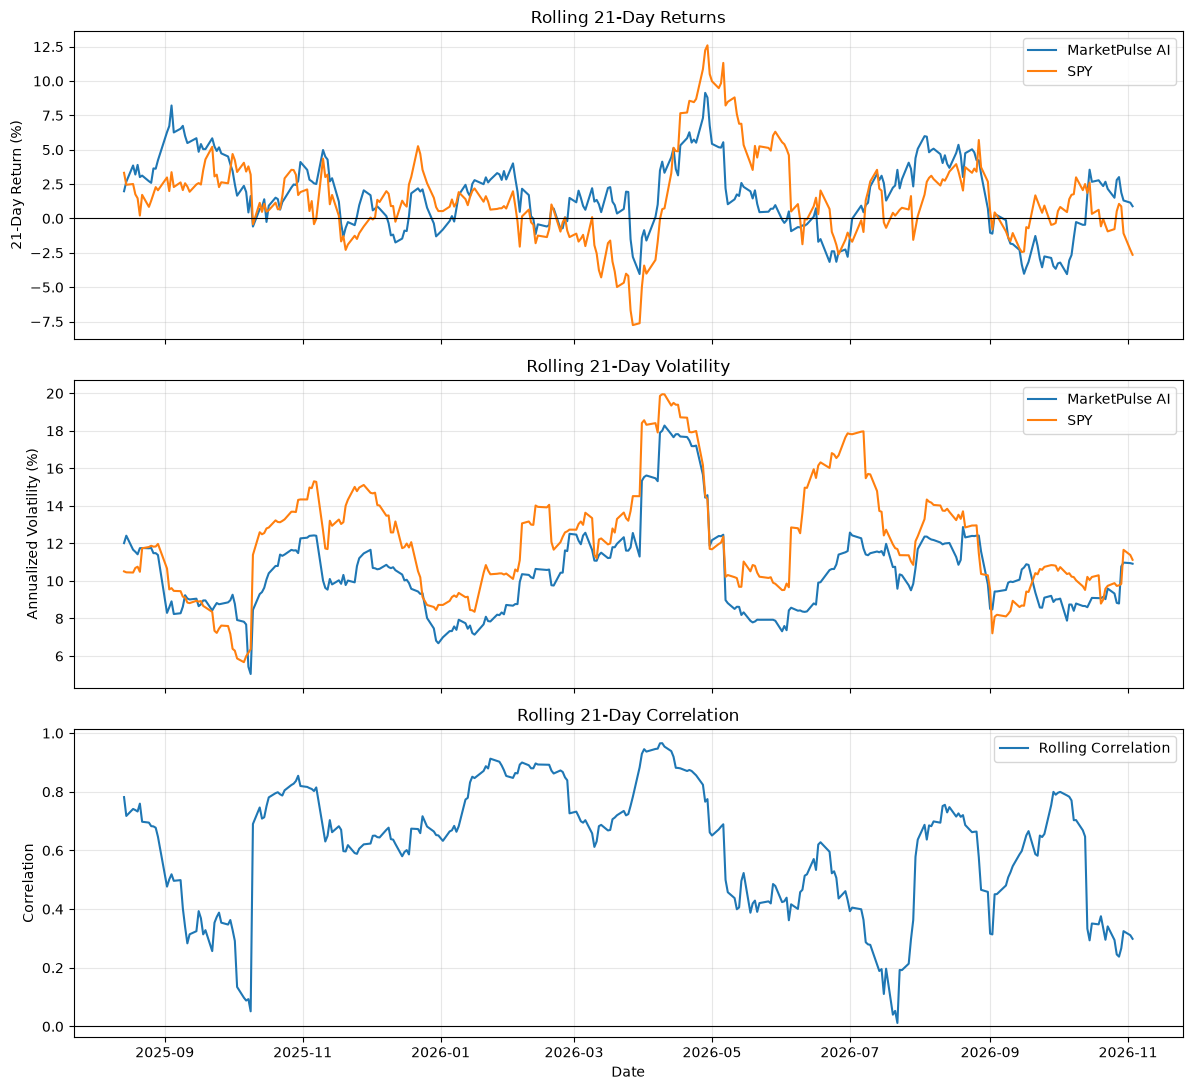


Cell 9 verification: PASSED
Rolling performance analysis completed.


In [9]:

# Cell 9 - Rolling Performance and Stability Analysis

print("MARKETPULSE AI - ROLLING PERFORMANCE ANALYSIS")
print("-" * 55)

rolling_df = benchmark.copy()

rolling_df["date"] = pd.to_datetime(
    rolling_df["date"]
)

rolling_df = rolling_df.sort_values(
    "date"
).reset_index(drop=True)

rolling_window = 21
annual_trading_days = 252

# Recalculate daily returns from equity
rolling_df["strategy_daily_return"] = (
    rolling_df["equity"].pct_change()
)

rolling_df["spy_daily_return"] = (
    rolling_df["spy_equity"].pct_change()
)

# 21-day compounded returns
rolling_df["strategy_rolling_return"] = (
    rolling_df["equity"]
    / rolling_df["equity"].shift(rolling_window)
    - 1
)

rolling_df["spy_rolling_return"] = (
    rolling_df["spy_equity"]
    / rolling_df["spy_equity"].shift(rolling_window)
    - 1
)

rolling_df["rolling_excess_return"] = (
    rolling_df["strategy_rolling_return"]
    - rolling_df["spy_rolling_return"]
)

# Annualized rolling volatility
rolling_df["strategy_rolling_vol"] = (
    rolling_df["strategy_daily_return"]
    .rolling(rolling_window)
    .std(ddof=1)
    * np.sqrt(annual_trading_days)
)

rolling_df["spy_rolling_vol"] = (
    rolling_df["spy_daily_return"]
    .rolling(rolling_window)
    .std(ddof=1)
    * np.sqrt(annual_trading_days)
)

# Rolling correlation
rolling_df["rolling_correlation"] = (
    rolling_df["strategy_daily_return"]
    .rolling(rolling_window)
    .corr(rolling_df["spy_daily_return"])
)

valid_rolling = rolling_df.dropna(
    subset=[
        "strategy_rolling_return",
        "spy_rolling_return",
        "rolling_excess_return",
        "strategy_rolling_vol",
        "spy_rolling_vol",
        "rolling_correlation"
    ]
).copy()

print("\nROLLING PERFORMANCE SUMMARY")

rolling_summary = pd.DataFrame({
    "Metric": [
        "Rolling Window (Trading Days)",
        "Valid Rolling Observations",
        "Average Strategy Rolling Return (%)",
        "Average SPY Rolling Return (%)",
        "Best Strategy Rolling Return (%)",
        "Worst Strategy Rolling Return (%)",
        "Average Rolling Excess Return (%)",
        "Periods Strategy Outperformed (%)",
        "Average Strategy Rolling Volatility (%)",
        "Average SPY Rolling Volatility (%)",
        "Average Rolling Correlation"
    ],
    "Value": [
        rolling_window,
        len(valid_rolling),
        valid_rolling["strategy_rolling_return"].mean() * 100,
        valid_rolling["spy_rolling_return"].mean() * 100,
        valid_rolling["strategy_rolling_return"].max() * 100,
        valid_rolling["strategy_rolling_return"].min() * 100,
        valid_rolling["rolling_excess_return"].mean() * 100,
        (
            valid_rolling["rolling_excess_return"] > 0
        ).mean() * 100,
        valid_rolling["strategy_rolling_vol"].mean() * 100,
        valid_rolling["spy_rolling_vol"].mean() * 100,
        valid_rolling["rolling_correlation"].mean()
    ]
})

display(rolling_summary.round(4))

# Plot rolling performance
fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True
)

axes[0].plot(
    valid_rolling["date"],
    valid_rolling["strategy_rolling_return"] * 100,
    label="MarketPulse AI"
)

axes[0].plot(
    valid_rolling["date"],
    valid_rolling["spy_rolling_return"] * 100,
    label="SPY"
)

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("21-Day Return (%)")
axes[0].set_title("Rolling 21-Day Returns")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    valid_rolling["date"],
    valid_rolling["strategy_rolling_vol"] * 100,
    label="MarketPulse AI"
)

axes[1].plot(
    valid_rolling["date"],
    valid_rolling["spy_rolling_vol"] * 100,
    label="SPY"
)

axes[1].set_ylabel("Annualized Volatility (%)")
axes[1].set_title("Rolling 21-Day Volatility")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    valid_rolling["date"],
    valid_rolling["rolling_correlation"],
    label="Rolling Correlation"
)

axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_ylabel("Correlation")
axes[2].set_xlabel("Date")
axes[2].set_title("Rolling 21-Day Correlation")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Verification
assert len(valid_rolling) == len(rolling_df) - rolling_window

assert valid_rolling["rolling_correlation"].between(
    -1.000001, 1.000001
).all()

print("\nCell 9 verification: PASSED")
print("Rolling performance analysis completed.")


MARKETPULSE AI - SIGNAL CONFIDENCE ANALYSIS
-------------------------------------------------------

PREDICTED PROBABILITY RANGE
Minimum: 0.6001
Maximum: 0.7233
Mean: 0.6316

CONFIDENCE BAND PERFORMANCE


,confidence_band,trades,win_rate,average_return,median_return,total_pnl,average_probability
0,0.60-0.65,240,51.67,0.99,0.43,23721.47,62.28
1,0.65-0.70,53,52.83,0.11,0.47,600.91,66.19
2,0.70-0.75,6,50.00,1.67,-2.99,1003.83,71.43
3,0.75-0.80,0,NaN,NaN,NaN,0.00,NaN
4,0.80-1.00,0,NaN,NaN,NaN,0.00,NaN



CONFIDENCE-RETURN CORRELATION
-0.0141


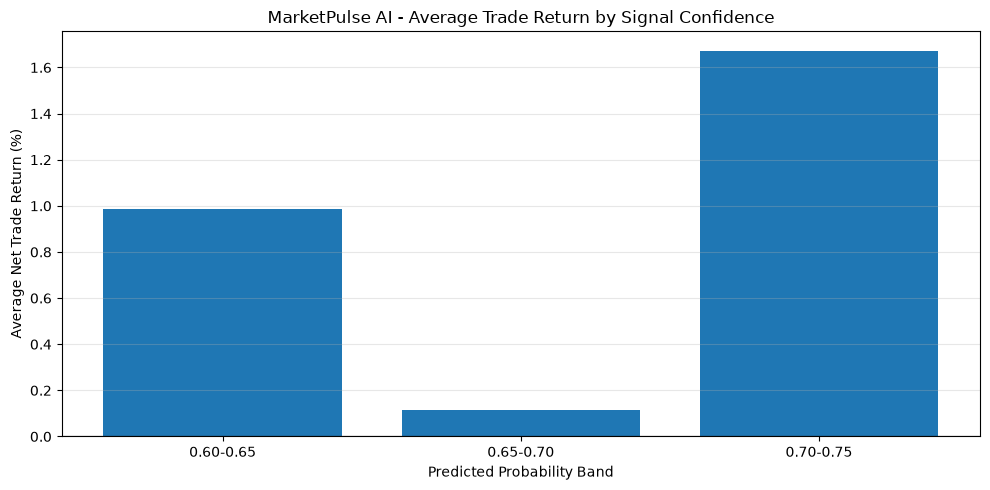


Cell 10 verification: PASSED
Signal confidence analysis completed.
Trading threshold remains unchanged at 0.60.


In [10]:

# Cell 10 - Model Signal Confidence Analysis

print("MARKETPULSE AI - SIGNAL CONFIDENCE ANALYSIS")
print("-" * 55)

confidence_df = trades.copy()

# Verify required columns
assert confidence_df[
    ["predicted_probability", "net_return", "pnl"]
].notna().all().all()

print("\nPREDICTED PROBABILITY RANGE")

print(
    "Minimum:",
    round(confidence_df["predicted_probability"].min(), 4)
)

print(
    "Maximum:",
    round(confidence_df["predicted_probability"].max(), 4)
)

print(
    "Mean:",
    round(confidence_df["predicted_probability"].mean(), 4)
)

# Fixed probability ranges
confidence_bins = [0.60, 0.65, 0.70, 0.75, 0.80, 1.000001]

confidence_labels = [
    "0.60-0.65",
    "0.65-0.70",
    "0.70-0.75",
    "0.75-0.80",
    "0.80-1.00"
]

confidence_df["confidence_band"] = pd.cut(
    confidence_df["predicted_probability"],
    bins=confidence_bins,
    labels=confidence_labels,
    right=False,
    include_lowest=True
)

# Summarize performance by confidence band
confidence_summary = (
    confidence_df
    .groupby("confidence_band", observed=False)
    .agg(
        trades=("pnl", "count"),
        win_rate=("pnl", lambda x: (x > 0).mean()),
        average_return=("net_return", "mean"),
        median_return=("net_return", "median"),
        total_pnl=("pnl", "sum"),
        average_probability=(
            "predicted_probability", "mean"
        )
    )
    .reset_index()
)

# Convert proportions to percentages for display
confidence_display = confidence_summary.copy()

for col in [
    "win_rate",
    "average_return",
    "median_return",
    "average_probability"
]:
    confidence_display[col] *= 100

print("\nCONFIDENCE BAND PERFORMANCE")
display(confidence_display.round(2))

# Correlation between confidence and realized return
confidence_return_corr = (
    confidence_df["predicted_probability"]
    .corr(confidence_df["net_return"])
)

print("\nCONFIDENCE-RETURN CORRELATION")
print(round(confidence_return_corr, 4))

# Plot average return by confidence band
plot_df = confidence_summary[
    confidence_summary["trades"] > 0
].copy()

plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["confidence_band"].astype(str),
    plot_df["average_return"] * 100
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title(
    "MarketPulse AI - Average Trade Return by Signal Confidence"
)

plt.xlabel("Predicted Probability Band")
plt.ylabel("Average Net Trade Return (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Verification
assert len(confidence_df) == 299

assert confidence_summary["trades"].sum() == 299

assert np.isclose(
    confidence_summary["total_pnl"].sum(),
    trades["pnl"].sum()
)

assert confidence_df["confidence_band"].notna().all()

print("\nCell 10 verification: PASSED")
print("Signal confidence analysis completed.")
print("Trading threshold remains unchanged at 0.60.")


MARKETPULSE AI - PREDICTION CALIBRATION
-------------------------------------------------------

PREDICTION DATA
Shape: (6400, 6)
Columns: ['date', 'ticker', 'target_return_10d', 'target_direction_10d', 'predicted_probability', 'signal']

OVERALL CALIBRATION METRICS


,Metric,Value
0,Test Observations,6400.0000
1,Actual Positive Rate,0.5433
2,Average Predicted Probability,0.5710
3,Model ROC AUC,0.5125
4,Model Brier Score,0.2510
5,Constant Baseline Brier Score,0.2481
6,Model Log Loss,0.6956
7,Constant Baseline Log Loss,0.6894



CALIBRATION BY PROBABILITY BIN


,probability_bin,observations,mean_predicted_probability,actual_positive_rate
0,"(-0.001, 0.1]",0,NaN,<NA>
1,"(0.1, 0.2]",0,NaN,<NA>
2,"(0.2, 0.3]",0,NaN,<NA>
3,"(0.3, 0.4]",6,0.3892,1.0
4,"(0.4, 0.5]",718,0.4714,0.4889
5,"(0.5, 0.6]",3588,0.5540,0.5424
6,"(0.6, 0.7]",2042,0.6332,0.569
7,"(0.7, 0.8]",46,0.7184,0.2609
8,"(0.8, 0.9]",0,NaN,<NA>
9,"(0.9, 1.0]",0,NaN,<NA>


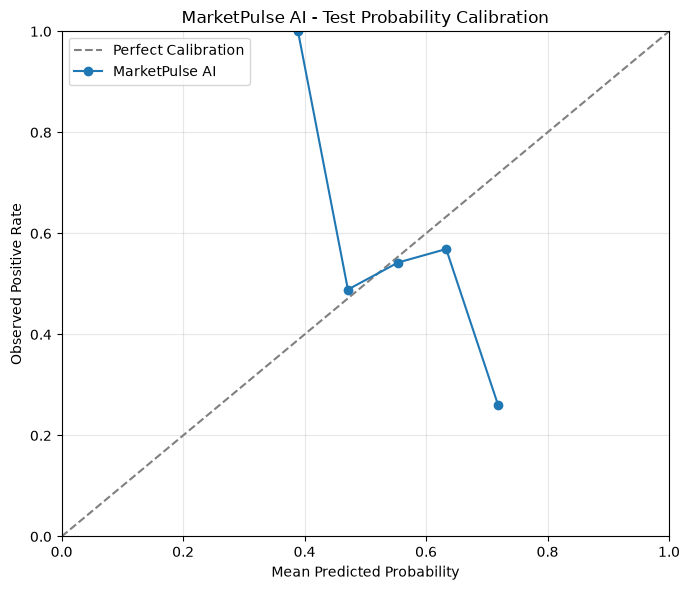


Cell 11 verification: PASSED
Calibration analysis completed.
Model and trading threshold: UNCHANGED


In [11]:

# Cell 11 - Out-of-Sample Prediction Calibration

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)

print("MARKETPULSE AI - PREDICTION CALIBRATION")
print("-" * 55)

predictions_path = (
    results_dir / "marketpulse_test_predictions.parquet"
)

predictions = pd.read_parquet(predictions_path)

print("\nPREDICTION DATA")
print("Shape:", predictions.shape)
print("Columns:", predictions.columns.tolist())

required_columns = [
    "target_direction_10d",
    "predicted_probability"
]

assert all(
    col in predictions.columns
    for col in required_columns
)

calibration_df = predictions[
    required_columns
].dropna().copy()

y_true = calibration_df[
    "target_direction_10d"
].astype(int)

y_prob = calibration_df[
    "predicted_probability"
].astype(float)

assert y_true.isin([0, 1]).all()
assert y_prob.between(0, 1).all()

# Baseline predicts the observed positive class frequency.
# This is descriptive, not a deployable baseline.
base_rate = y_true.mean()

baseline_prob = np.full(
    len(y_true), base_rate
)

model_brier = brier_score_loss(y_true, y_prob)

baseline_brier = brier_score_loss(
    y_true, baseline_prob
)

model_logloss = log_loss(
    y_true, y_prob, labels=[0, 1]
)

baseline_logloss = log_loss(
    y_true, baseline_prob, labels=[0, 1]
)

model_auc = roc_auc_score(y_true, y_prob)

print("\nOVERALL CALIBRATION METRICS")

calibration_metrics = pd.DataFrame({
    "Metric": [
        "Test Observations",
        "Actual Positive Rate",
        "Average Predicted Probability",
        "Model ROC AUC",
        "Model Brier Score",
        "Constant Baseline Brier Score",
        "Model Log Loss",
        "Constant Baseline Log Loss"
    ],
    "Value": [
        len(y_true),
        base_rate,
        y_prob.mean(),
        model_auc,
        model_brier,
        baseline_brier,
        model_logloss,
        baseline_logloss
    ]
})

display(calibration_metrics.round(4))

# Fixed probability bins
bins = np.linspace(0, 1, 11)

calibration_df["probability_bin"] = pd.cut(
    y_prob,
    bins=bins,
    include_lowest=True
)

calibration_summary = (
    calibration_df
    .groupby("probability_bin", observed=False)
    .agg(
        observations=("target_direction_10d", "size"),
        mean_predicted_probability=(
            "predicted_probability", "mean"
        ),
        actual_positive_rate=(
            "target_direction_10d", "mean"
        )
    )
    .reset_index()
)

print("\nCALIBRATION BY PROBABILITY BIN")
display(calibration_summary.round(4))

plot_calibration = calibration_summary[
    calibration_summary["observations"] > 0
].copy()

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.plot(
    plot_calibration["mean_predicted_probability"],
    plot_calibration["actual_positive_rate"],
    marker="o",
    label="MarketPulse AI"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Rate")
plt.title("MarketPulse AI - Test Probability Calibration")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Verification
assert len(calibration_df) == 6400
assert calibration_summary["observations"].sum() == 6400

print("\nCell 11 verification: PASSED")
print("Calibration analysis completed.")
print("Model and trading threshold: UNCHANGED")


In [12]:

# Cell 12 - Strategy Robustness Summary

print("MARKETPULSE AI - STRATEGY ROBUSTNESS SUMMARY")
print("-" * 55)

# Collect verified results from previous cells
robustness_metrics = [
    {
        "Category": "Portfolio",
        "Metric": "Executed Trades",
        "Value": len(trades),
        "Interpretation": "299 simulated executions"
    },
    {
        "Category": "Portfolio",
        "Metric": "Cumulative Return (%)",
        "Value": (
            performance.loc[
                "Cumulative_Return", "MarketPulse_AI"
            ] * 100
        ),
        "Interpretation": "Positive simulated return"
    },
    {
        "Category": "Benchmark",
        "Metric": "SPY Cumulative Return (%)",
        "Value": (
            performance.loc[
                "Cumulative_Return", "SPY_Buy_Hold"
            ] * 100
        ),
        "Interpretation": "Benchmark comparison"
    },
    {
        "Category": "Trading",
        "Metric": "Win Rate (%)",
        "Value": win_rate * 100,
        "Interpretation": "Slightly above 50%"
    },
    {
        "Category": "Trading",
        "Metric": "Profit Factor",
        "Value": profit_factor,
        "Interpretation": "Profits exceeded losses"
    },
    {
        "Category": "Concentration",
        "Metric": "Top 10 Trades / Net Profit (%)",
        "Value": (
            concentration_df.loc[
                concentration_df["Top_N_Trades"] == 10,
                "Pct_of_Net_Profit"
            ].iloc[0]
        ),
        "Interpretation": "High profit concentration"
    },
    {
        "Category": "Risk",
        "Metric": "Strategy Maximum Drawdown (%)",
        "Value": strategy_dd["max_drawdown"] * 100,
        "Interpretation": "Smaller simulated drawdown than SPY"
    },
    {
        "Category": "Risk",
        "Metric": "Portfolio Beta",
        "Value": beta,
        "Interpretation": "Lower market sensitivity"
    },
    {
        "Category": "Model",
        "Metric": "Test ROC AUC",
        "Value": model_auc,
        "Interpretation": "Weak predictive discrimination"
    },
    {
        "Category": "Model",
        "Metric": "Model Brier Score",
        "Value": model_brier,
        "Interpretation": "Worse than constant baseline"
    },
    {
        "Category": "Model",
        "Metric": "Constant Baseline Brier Score",
        "Value": baseline_brier,
        "Interpretation": "Retrospective reference"
    }
]

robustness_summary = pd.DataFrame(
    robustness_metrics
)

print("\nROBUSTNESS ASSESSMENT")
display(robustness_summary.round(4))

# Verification
assert len(trades) == 299
assert profit_factor > 1
assert model_auc < 0.55
assert model_brier > baseline_brier

print("\nKEY LIMITATIONS")

limitations = [
    "Weak out-of-sample model discrimination",
    "Poor probability calibration relative to baseline",
    "High concentration of profits in top winning trades",
    "Adjusted OHLC used as execution-price proxy",
    "SPY benchmark transaction costs not aligned",
    "Fractional shares and fixed position sizing assumed",
    "Potential survivorship and point-in-time data biases",
    "No market-impact or liquidity constraints",
    "Single historical out-of-sample evaluation period"
]

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")

print("\nCell 12 verification: PASSED")
print("Robustness summary completed.")
print("Model parameters and threshold: UNCHANGED")


MARKETPULSE AI - STRATEGY ROBUSTNESS SUMMARY
-------------------------------------------------------

ROBUSTNESS ASSESSMENT


,Category,Metric,Value,Interpretation
0,Portfolio,Executed Trades,299.0000,299 simulated executions
1,Portfolio,Cumulative Return (%),25.3262,Positive simulated return
2,Benchmark,SPY Cumulative Return (%),22.5835,Benchmark comparison
3,Trading,Win Rate (%),51.8395,Slightly above 50%
4,Trading,Profit Factor,1.4213,Profits exceeded losses
5,Concentration,Top 10 Trades / Net Profit (%),79.3033,High profit concentration
6,Risk,Strategy Maximum Drawdown (%),-5.2357,Smaller simulated drawdown than SPY
7,Risk,Portfolio Beta,0.5531,Lower market sensitivity
8,Model,Test ROC AUC,0.5125,Weak predictive discrimination
9,Model,Model Brier Score,0.2510,Worse than constant baseline



KEY LIMITATIONS
1. Weak out-of-sample model discrimination
2. Poor probability calibration relative to baseline
3. High concentration of profits in top winning trades
4. Adjusted OHLC used as execution-price proxy
5. SPY benchmark transaction costs not aligned
6. Fractional shares and fixed position sizing assumed
7. Potential survivorship and point-in-time data biases
8. No market-impact or liquidity constraints
9. Single historical out-of-sample evaluation period

Cell 12 verification: PASSED
Robustness summary completed.
Model parameters and threshold: UNCHANGED


In [13]:

# Cell 13 - Save Strategy Analysis Results

from pathlib import Path
import pandas as pd
import numpy as np

print("MARKETPULSE AI - SAVE STRATEGY ANALYSIS")
print("-" * 55)

analysis_dir = project_root / "results" / "strategy_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

# Prepare analysis artifacts
analysis_artifacts = {
    "trade_summary.csv": trade_summary,
    "ticker_performance.csv": ticker_performance,
    "profit_concentration.csv": concentration_df,
    "portfolio_exposure.csv": exposure_df,
    "position_distribution.csv": position_distribution,
    "drawdown_summary.csv": drawdown_summary,
    "monthly_performance.csv": monthly_display,
    "benchmark_risk_summary.csv": risk_summary,
    "rolling_performance.csv": valid_rolling,
    "confidence_band_performance.csv": confidence_summary,
    "calibration_metrics.csv": calibration_metrics,
    "calibration_by_probability.csv": calibration_summary,
    "robustness_summary.csv": robustness_summary
}

print("\nSAVING ANALYSIS ARTIFACTS")

saved_files = []

for filename, dataframe in analysis_artifacts.items():

    output_path = analysis_dir / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    assert output_path.exists()

    reloaded = pd.read_csv(output_path)

    assert len(reloaded) == len(dataframe)

    saved_files.append(filename)

    print(
        f"{filename}: SAVED "
        f"({len(dataframe):,} rows)"
    )

print("\nVERIFICATION")

print("Total artifacts saved:", len(saved_files))
print("Output directory:", analysis_dir)

assert len(saved_files) == 13

# Verify critical summary values
saved_robustness = pd.read_csv(
    analysis_dir / "robustness_summary.csv"
)

saved_return = saved_robustness.loc[
    saved_robustness["Metric"] == "Cumulative Return (%)",
    "Value"
].iloc[0]

assert np.isclose(saved_return, 25.3262, atol=1e-3)

print(
    "Verified simulated return:",
    f"{saved_return:.2f}%"
)

print("\nCell 13 verification: PASSED")
print("Strategy analysis artifacts saved successfully.")


MARKETPULSE AI - SAVE STRATEGY ANALYSIS
-------------------------------------------------------

SAVING ANALYSIS ARTIFACTS
trade_summary.csv: SAVED (15 rows)
ticker_performance.csv: SAVED (19 rows)
profit_concentration.csv: SAVED (4 rows)
portfolio_exposure.csv: SAVED (329 rows)
position_distribution.csv: SAVED (9 rows)
drawdown_summary.csv: SAVED (6 rows)
monthly_performance.csv: SAVED (17 rows)
benchmark_risk_summary.csv: SAVED (7 rows)
rolling_performance.csv: SAVED (308 rows)
confidence_band_performance.csv: SAVED (5 rows)
calibration_metrics.csv: SAVED (8 rows)
calibration_by_probability.csv: SAVED (10 rows)
robustness_summary.csv: SAVED (11 rows)

VERIFICATION
Total artifacts saved: 13
Output directory: C:\Users\roban\marketpulse-ai\results\strategy_analysis
Verified simulated return: 25.33%

Cell 13 verification: PASSED
Strategy analysis artifacts saved successfully.



## Final Strategy Analysis and Conclusions

### 1. Project Overview

MarketPulse AI evaluates a machine-learning-based stock trading
strategy using historical market data, macroeconomic indicators,
and sentiment data.

The selected Random Forest classifier predicts the direction
of stock returns over a 10-trading-day horizon.

The trading strategy uses a fixed 0.60 probability threshold,
a maximum of 10 concurrent positions, and an initial portfolio
capital of $100,000.

### 2. Out-of-Sample Backtest Results

| Metric | MarketPulse AI | SPY |
|---|---:|---:|
| Cumulative Return | 25.33% | 22.58% |
| Annualized Return | 18.94% | 16.93% |
| Annualized Volatility | 10.69% | 12.30% |
| Sharpe Ratio | 1.6768 | 1.3292 |
| Maximum Drawdown | -5.24% | -8.88% |

The corrected simulation executed 299 trades and generated
$25,326.20 in net portfolio profit.

### 3. Trading Performance

- Win rate: 51.84%
- Profit factor: 1.4213
- Average net trade return: 0.85%
- Profitable tickers: 17 of 19 traded
- Top 10 winning trades contributed 79.30% of net profit

The strategy's profitability was sensitive to a relatively
small number of large winning trades.

### 4. Portfolio Risk and Exposure

- Average invested capital: 78.91%
- Average open positions: 9.09
- Portfolio beta versus SPY: 0.5531
- Annualized tracking error: 9.91%
- Information ratio: 0.1590

The strategy exhibited lower historical market sensitivity
than SPY, but its relative-return consistency was limited.

### 5. Machine Learning Model Evaluation

- Test ROC AUC: 0.5125
- Model Brier score: 0.2510
- Retrospective constant-baseline Brier score: 0.2481
- Confidence-to-trade-return correlation: -0.0141

The classifier showed weak out-of-sample discrimination,
and its predicted probabilities were less accurate than
the retrospective constant-probability baseline.

Positive simulated portfolio returns therefore do not
establish reliable predictive ability.

### 6. Methodology Limitations

1. Adjusted OHLC prices were used as execution-price proxies.
2. SPY benchmark transaction costs were not aligned.
3. Fractional shares and fixed position allocations were assumed.
4. Current stock-universe selection may introduce survivorship bias.
5. Macroeconomic and sentiment inputs may have point-in-time
   availability or revision limitations.
6. Market impact and liquidity constraints were not modeled.
7. The analysis used one historical out-of-sample test period.
8. Overlapping prediction horizons limit statistical independence.
9. Trading profitability was concentrated in large winning trades.

### 7. Final Conclusion

MarketPulse AI demonstrated positive simulated performance
and exceeded the SPY benchmark over the evaluation period.

However, weak model discrimination, imperfect calibration,
profit concentration, and backtesting assumptions prevent
the results from establishing a robust or deployable
trading advantage.

The project demonstrates an end-to-end financial machine
learning workflow, including data collection, feature
engineering, model evaluation, chronological backtesting,
risk analysis, and reproducible reporting.

### 8. Future Improvements

Potential improvements include:

- Point-in-time data validation
- More realistic execution and transaction-cost modeling
- Walk-forward validation across multiple market regimes
- Probability calibration using validation data
- Additional benchmark and strategy comparisons
- Paper-trading evaluation before any live deployment
